# 00 · Planteamiento del caso y teoría de cambio
**Caso 5: ampliación del horario de cuidado infantil**

| Notebook | Etapa | Pregunta que responde |
|---|---|---|
| **00** | **Planteamiento y teoría de cambio** | ¿Qué queremos medir y por qué? |
| 01 | Auditoría de datos y construcción de variables | ¿Los datos son confiables? |
| 02 | Diseño muestral y validez interna | ¿El sorteo fue limpio y los grupos comparables? |
| 03 | Análisis exploratorio (EDA) | ¿Cómo son las madres y sus resultados? |
| 04 | Análisis causal | ¿Cuánto cambió la intervención los resultados? |
| 05 | Sensibilidad y robustez | ¿Se sostienen las conclusiones si cambian los supuestos? |

Cada etapa sigue la misma estructura: **objetivo y justificación → fundamento metodológico → código → interpretación → supuestos y limitaciones → decisión para la siguiente etapa**. Los términos técnicos se explican en recuadros **"En sencillo"**, y las referencias bibliográficas, numeradas como [n], están al final de cada notebook.

Este notebook es mayormente conceptual: fija *antes de mirar los resultados* qué se quiere estimar, por qué y con qué variables. Así, las decisiones de los notebooks siguientes no se toman en función de lo que sale significativo.

### Preparación del entorno

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Rutas relativas a la raíz del repositorio
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "caso05_cuidado_infantil.dta"
PROCESSED = ROOT / "data" / "processed" / "caso05_analitico.csv"

# Roles de las variables (definidos en 00_planteamiento_teoria_cambio)
ID, CENTER = "hogar_id", "centro_id"
Z = "oferta_sorteo"            # asignación aleatoria (instrumento)
D = "uso_horario_ampliado"     # tratamiento recibido (endógeno)
BASELINE = [
    "edad_madre", "numero_hijos", "edad_menor", "educ_madre", "madre_sola",
    "traslado_min", "red_cuidado", "empleo_pre", "horas_pre", "ingreso_pre",
]
OUTCOMES = ["empleo_post", "horas_post", "ingreso_post_c", "bienestar_post"]
ALPHA, SEED = 0.05, 2026

# Estilo gráfico: oferta = azul, sin oferta = naranja; grilla recesiva
COLORS = {0: "#eb6834", 1: "#2a78d6"}
LABELS = {0: "Sin oferta (Z=0)", 1: "Con oferta (Z=1)"}
NEUTRAL = "#8a8984"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e6e6e3", "figure.dpi": 110, "axes.titleweight": "bold",
})

## 0.1 Planteamiento del caso

**Objetivo.** Delimitar la intervención, la población, la comparación y los resultados, y formular la pregunta causal.

**Justificación.** Un efecto causal solo tiene sentido respecto de una intervención y un **contrafactual** bien definidos. Si no se precisa, se confunde el efecto de *ofrecer* el servicio con el de *usarlo*.

> **En sencillo — contrafactual:** es "lo que habría pasado sin la intervención". Nunca se observa para la misma persona (una madre fue sorteada o no, pero no ambas cosas). Por eso se aproxima con un grupo de comparación que, en promedio, se le parezca.

**Contexto.** Las responsabilidades de cuidado de hijos pequeños limitan la participación laboral de las madres, sobre todo cuando el horario del centro no cubre la jornada laboral ni el traslado. Se amplió el horario de centros de cuidado infantil y, como las vacantes eran limitadas, la oferta se asignó **por sorteo** entre las madres u hogares postulantes.

> **Nota:** el diccionario no describe el programa en detalle (duración, horario exacto, costo, período entre la línea de base y el seguimiento). Esos elementos se tratan como supuestos explícitos y deben verificarse con la documentación del programa.

El caso se ordena con el **marco PICO** (Población, Intervención, Comparación, *Outcomes* o resultados), una lista de verificación para que la pregunta quede completa:

| Componente | Definición en este caso |
|---|---|
| **P**oblación | 1 500 madres u hogares que **postularon** a 5 centros de cuidado infantil (unidad: madre u hogar postulante) |
| **I**ntervención | Oferta de vacante con horario ampliado, asignada por sorteo (`oferta_sorteo`); uso efectivo registrado en `uso_horario_ampliado` |
| **C**omparación | Postulantes no sorteadas, que conservan sus alternativas de cuidado (horario regular, red familiar, otros) |
| **O**utcomes (resultados) | Primario: empleo. Secundarios: horas semanales, ingreso laboral mensual, bienestar (0-100) |
| Diseño | Experimento con sorteo estratificado por centro (se infiere de los datos en 02), cumplimiento imperfecto y medición antes y después |

> **En sencillo — cumplimiento imperfecto:** no todas las sorteadas usaron el servicio y algunas no sorteadas sí lo usaron. "Ser sorteada" y "usar el servicio" no son lo mismo, y eso obliga a medir dos efectos distintos (ver 0.2).

**Preguntas causales**

1. **Política (principal):** ¿cuál es el efecto de *ofrecer* el horario ampliado sobre el empleo, las horas, el ingreso y el bienestar de las madres postulantes? → **ITT**
2. **Mecanismo:** ¿cuál es el efecto de *usar* el horario ampliado entre las madres que lo usan *porque* recibieron la oferta? → **LATE**
3. **Focalización:** ¿el efecto es mayor donde la restricción de cuidado es más fuerte (madres solas, sin red de cuidado)? → **heterogeneidad**

## 0.2 Estimandos

Un **estimando** es la cantidad exacta que se quiere conocer, definida antes de elegir el método para calcularla.

**Fundamento metodológico.** Se usa el lenguaje de **resultados potenciales**. $D_i(1)$ y $D_i(0)$ indican si la madre $i$ usaría el servicio si fuera sorteada o si no lo fuera. $Y_i(z, d)$ es el resultado que tendría con sorteo $z$ y uso $d$. Bajo el supuesto de exclusión (abajo), el sorteo no importa por sí mismo y se escribe simplemente $Y_i(d)$: el resultado con uso ($d=1$) o sin uso ($d=0$). El sorteo de $Z$ permite medir directamente los efectos de la *asignación*. El efecto del *uso* requiere supuestos adicionales de **variables instrumentales** [1, 2].

> **En sencillo — variable instrumental:** es algo que empuja a las personas a recibir el tratamiento y que no afecta el resultado por ninguna otra vía. Aquí el sorteo cumple ese papel: cambia la probabilidad de usar el servicio, pero (se supone) solo influye en el empleo *a través* del uso. Así se aísla el efecto del uso sin que interfieran las razones personales por las que alguien decide usarlo.

| Estimando | Definición | Qué se necesita para medirlo | Pregunta que responde |
|---|---|---|---|
| **ITT** (*intention to treat*, efecto de la intención de tratar) | $E[Y_i(1, D_i(1)) - Y_i(0, D_i(0))]$ | Solo el sorteo | Efecto de la política tal como se implementa |
| **Primera etapa** ($\pi$) | $E[D_i(1)-D_i(0)]$ | Solo el sorteo | Cuánto cambia el uso por ofrecer la vacante (= proporción de cumplidoras) |
| **LATE** (*local average treatment effect*, efecto promedio local) | $E[Y_i(d{=}1)-Y_i(d{=}0)\mid D_i(1)>D_i(0)] = ITT/\pi$ | Sorteo + exclusión + monotonicidad + relevancia | Efecto de usar el servicio entre las **cumplidoras** |
| ATE del uso | $E[Y_i(d{=}1)-Y_i(d{=}0)]$ | **No se puede medir** sin supuestos fuertes | No se estima |

> **En sencillo — los tres supuestos del LATE:**
> - **Exclusión:** el sorteo afecta los resultados *solo* porque cambia el uso del servicio, no por otra vía.
> - **Monotonicidad:** nadie hace lo contrario de lo que el sorteo empuja. No existe una madre que usaría el servicio si *no* la sortean y lo dejaría si la sortean.
> - **Relevancia:** el sorteo realmente cambia el uso (se verifica con los datos).
>
> **Tipos de madres según su respuesta al sorteo:** las **cumplidoras** usan el servicio si y solo si son sorteadas. Las **siempre usuarias** lo usan con o sin sorteo. Las **nunca usuarias** no lo usan aunque las sorteen. El LATE habla solo de las cumplidoras.

$E[\cdot]$ significa "promedio en la población".

**Por qué no comparar usuarias con no usuarias.** El uso es una decisión de la madre. Quienes usan el servicio sin haber sido sorteadas, o rechazan la vacante ofrecida, probablemente difieren en motivación, oportunidades laborales o restricciones que no se observan. Comparar por uso mezcla el efecto del servicio con esas diferencias. Esto se conoce como **sesgo de selección** y se documenta en 03 y 04.

## 0.3 Teoría de cambio

**Objetivo.** Hacer explícita la cadena causal que va de la intervención a los resultados, y los supuestos que deben cumplirse en cada eslabón.

> **En sencillo — teoría de cambio:** es la historia de "cómo y por qué" la intervención debería funcionar, paso a paso: qué se hace, qué produce, qué cambia en la vida de las personas y qué tiene que ser cierto en cada paso para que la cadena no se rompa.

**Justificación.** La teoría de cambio (i) define qué resultados deberían moverse y en qué orden, (ii) sugiere qué subgrupos deberían responder más (heterogeneidad definida de antemano) y (iii) señala qué variables son **mediadoras** (pasos intermedios del efecto), que no deben usarse como controles.

| Eslabón | Contenido | Supuesto crítico | Cómo se verifica con los datos |
|---|---|---|---|
| Insumos | Financiamiento y personal para ampliar el horario en 5 centros | Capacidad efectiva de atención | No observable |
| Actividades | Sorteo de vacantes; operación del horario ampliado | Sorteo limpio, sin manipulación | Balance y mecanismo de asignación (02) |
| Productos | Madres sorteadas usan el horario ampliado | Demanda efectiva; servicio accesible y de calidad aceptable | Primera etapa: diferencia de uso entre sorteadas y no sorteadas (02, 04) |
| Resultado intermedio | Más tiempo disponible y menor restricción de cuidado | El cuidado era lo que limitaba el empleo | Heterogeneidad por madre sola / red de cuidado (04) |
| Resultados | **Margen extensivo:** más empleo. **Margen intensivo:** más horas | Hay demanda laboral para ese tiempo adicional | ITT y LATE sobre empleo y horas (04) |
| | Más ingreso laboral | Empleos remunerados; las horas adicionales se pagan | ITT sobre ingreso (04); robustez a faltantes (05) |
| Impacto | Mayor bienestar | El ingreso y la autonomía compensan la mayor carga de trabajo | ITT sobre bienestar; signo ambiguo *a priori* |

> **En sencillo — margen extensivo e intensivo:** el **extensivo** es *si* la madre trabaja o no (pasar de 0 a trabajar). El **intensivo** es *cuánto* trabaja o gana quien ya trabaja (más horas, más ingreso por hora).

**Hipótesis definidas de antemano**

- **H1:** la oferta aumenta el empleo (resultado primario).
- **H2-H3:** la oferta aumenta las horas trabajadas y el ingreso laboral, medidos en toda la población y no solo entre las empleadas.
- **H4:** efecto sobre el bienestar de signo incierto (más ingreso frente a doble jornada).
- **H5 (heterogeneidad):** efectos mayores en madres solas y en hogares **sin red de cuidado** alternativa, donde la restricción pesa más, y menores en quienes ya trabajaban antes, que tienen menos margen para empezar a trabajar.

## 0.4 Grafo causal (DAG) y rol de las variables

**Fundamento metodológico.** Los supuestos causales se dibujan con un **grafo acíclico dirigido (DAG)** [3].

> **En sencillo — DAG:** es un dibujo de variables unidas por flechas. Cada flecha $A \to B$ dice "$A$ influye en $B$". Es *dirigido* porque las flechas tienen sentido, y *acíclico* porque ninguna cadena de flechas vuelve a su punto de partida (no hay causalidad circular).
>
> **¿Por qué "codifica supuestos"?** Cada flecha dibujada es una afirmación sobre cómo funciona el mundo, y **cada flecha que falta también lo es**. Por ejemplo, no dibujar una flecha directa del sorteo al empleo es afirmar que el sorteo solo influye en el empleo a través del uso del servicio. El DAG no se estima con los datos: es la teoría que se pone sobre la mesa para que cualquiera pueda discutirla. A partir de él se deduce con reglas precisas qué variables hay que controlar y cuáles no.

Esas reglas distinguen cuatro roles [4]:

| Rol | Forma en el DAG | Qué pasa si se controla por ella | Ejemplo cotidiano |
|---|---|---|---|
| **Confusora** | $T \leftarrow C \rightarrow Y$ | Hay que controlarla: si no, el efecto aparente mezcla el de $T$ con el de $C$ | El calor aumenta tanto la venta de helados como los ahogamientos; sin controlar por el calor, parecería que los helados causan ahogamientos |
| **Mediadora** | $T \rightarrow M \rightarrow Y$ | No se debe controlar: borra parte del efecto que se quiere medir | Si un fertilizante funciona porque las plantas crecen más altas, comparar plantas *de igual altura* oculta su efecto |
| **Colisionador** | $T \rightarrow K \leftarrow U$ | No se debe controlar: crea una relación falsa entre $T$ y $U$ | Si a una universidad se entra por talento *o* por deporte, entre los admitidos, quien no es deportista tiende a ser más talentoso, aunque en la población no haya relación |
| **Predictora del resultado** | $X \rightarrow Y$, sin flecha hacia $T$ | Opcional: no cambia el sesgo pero hace la estimación más precisa | — |

Como el sorteo es aleatorio, el rol de las covariables depende de qué efecto se estime:

- Para el efecto de la **oferta** ($Z \to Y$) no hay confusoras: el azar decidió quién fue sorteada. Las características previas solo sirven para ganar **precisión**, y el centro es una **variable de diseño** (el sorteo se hizo dentro de cada centro).
- Para el efecto del **uso** ($D \to Y$) las características previas y los no observables ($U$: motivación, oportunidades laborales, preferencias) **sí son confusoras**. Por eso el efecto del uso se mide con $Z$ como instrumento y no simplemente controlando por $X$.

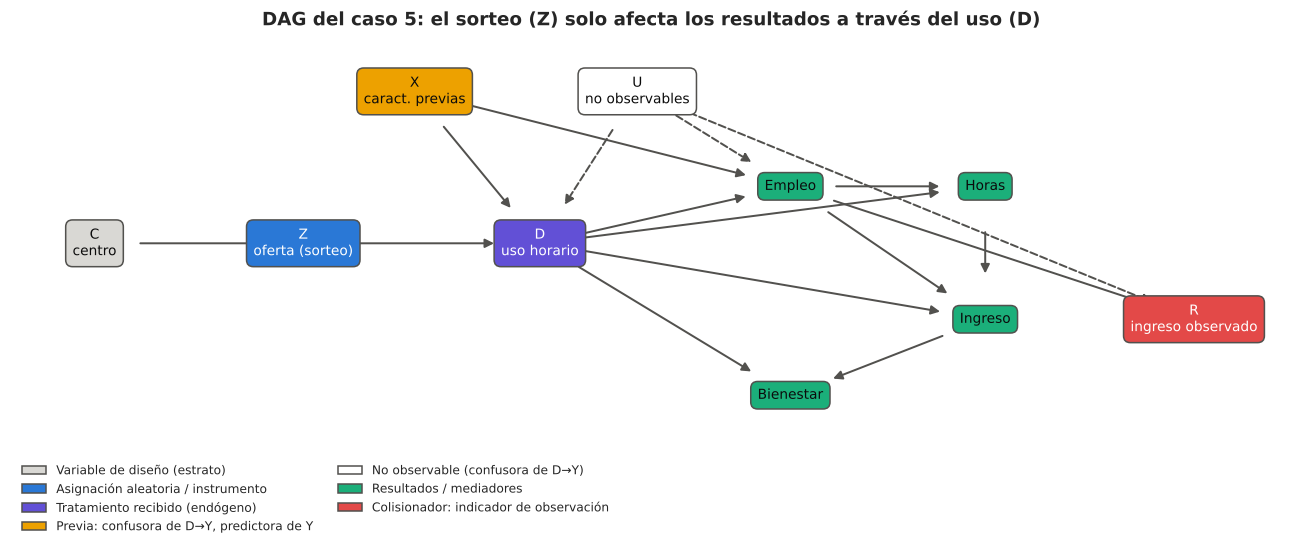

In [2]:
# DAG del caso: nodos y aristas según la teoría de cambio
import matplotlib.patches as mpatches

nodos = {
    "C\ncentro":            (0.0, 2.0, "diseno"),
    "Z\noferta (sorteo)":   (1.5, 2.0, "asignacion"),
    "D\nuso horario":       (3.2, 2.0, "tratamiento"),
    "X\ncaract. previas":   (2.3, 3.6, "previa"),
    "U\nno observables":    (3.9, 3.6, "noobs"),
    "Empleo":               (5.0, 2.6, "resultado"),
    "Horas":                (6.4, 2.6, "resultado"),
    "Ingreso":              (6.4, 1.2, "resultado"),
    "Bienestar":            (5.0, 0.4, "resultado"),
    "R\ningreso observado": (7.9, 1.2, "colisionador"),
}
aristas = [
    ("C\ncentro", "Z\noferta (sorteo)"), ("Z\noferta (sorteo)", "D\nuso horario"),
    ("X\ncaract. previas", "D\nuso horario"), ("U\nno observables", "D\nuso horario"),
    ("X\ncaract. previas", "Empleo"), ("U\nno observables", "Empleo"),
    ("D\nuso horario", "Empleo"), ("D\nuso horario", "Bienestar"),
    ("D\nuso horario", "Horas"), ("D\nuso horario", "Ingreso"),
    ("Empleo", "Horas"), ("Horas", "Ingreso"), ("Empleo", "Ingreso"),
    ("Ingreso", "Bienestar"), ("Empleo", "R\ningreso observado"),
    ("U\nno observables", "R\ningreso observado"),
]
estilo = {
    "diseno": "#d9d8d4", "asignacion": "#2a78d6", "tratamiento": "#6250d6",
    "previa": "#eda100", "noobs": "#ffffff", "resultado": "#1baf7a", "colisionador": "#e34948",
}
nombres = {
    "diseno": "Variable de diseño (estrato)", "asignacion": "Asignación aleatoria / instrumento",
    "tratamiento": "Tratamiento recibido (endógeno)", "previa": "Previa: confusora de D→Y, predictora de Y",
    "noobs": "No observable (confusora de D→Y)", "resultado": "Resultados / mediadores",
    "colisionador": "Colisionador: indicador de observación",
}

fig, ax = plt.subplots(figsize=(12, 5.2))
for origen, destino in aristas:
    (x0, y0, _), (x1, y1, _) = nodos[origen], nodos[destino]
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color="#52514e", lw=1.3,
                                shrinkA=30, shrinkB=30,
                                linestyle="--" if origen.startswith("U") else "-"))
for nombre, (x, y, tipo) in nodos.items():
    texto_blanco = tipo in {"asignacion", "tratamiento", "colisionador"}
    ax.text(x, y, nombre, ha="center", va="center", fontsize=9,
            color="white" if texto_blanco else "#0b0b0b",
            bbox=dict(boxstyle="round,pad=0.5", fc=estilo[tipo], ec="#52514e", lw=1))
ax.legend(handles=[mpatches.Patch(fc=estilo[k], ec="#52514e", label=v) for k, v in nombres.items()],
          loc="lower left", fontsize=8, frameon=False, ncol=2, bbox_to_anchor=(0, -0.22))
ax.set_xlim(-0.6, 8.6); ax.set_ylim(-0.2, 4.2); ax.axis("off")
ax.set_title("DAG del caso 5: el sorteo (Z) solo afecta los resultados a través del uso (D)")
plt.tight_layout(); plt.show()

**Interpretación del DAG**

*(Por claridad, las flechas de $X$, $U$ y del centro hacia los resultados se dibujan solo hacia el empleo, pero afectan a todos los resultados.)*

- **$Z$ solo recibe una flecha, desde el centro.** Como el sorteo se hizo dentro de cada centro, al comparar dentro de cada centro no queda ningún camino "por la puerta de atrás" entre $Z$ y los resultados. El ITT se mide sin necesidad de controlar por covariables, y controlar por $X$ solo mejora la precisión.
- **$D$ recibe flechas de $X$ y de $U$.** Comparar usuarias con no usuarias está confundido, y como $U$ no se observa, controlar por $X$ no basta. La solución es usar $Z$ como instrumento. Esto exige que **no exista una flecha directa $Z \to Y$** (exclusión), lo que se discute y somete a sensibilidad en 05.
- **El uso afecta horas e ingreso por dos vías:** a través del empleo (más madres trabajando, margen extensivo) y directamente entre quienes ya trabajan (más horas o más ingreso, margen intensivo). Por eso hay flechas $D \to$ Horas y $D \to$ Ingreso además de $D \to$ Empleo.
- **El empleo es mediador** hacia horas, ingreso y bienestar. Estimar el efecto sobre el ingreso "controlando por empleo", o solo entre empleadas, borra parte del efecto. Además, el empleo es un **colisionador** entre el tratamiento y los no observables ($D \to \text{Empleo} \leftarrow U$): restringirse a las empleadas crea comparaciones engañosas.
- **$R$ (ingreso observado) también es un colisionador.** Analizar solo los casos con ingreso registrado equivale a filtrar por $R$ (la variable es un colisionador; el problema aparece al condicionar en ella). Por eso los faltantes de ingreso se diagnostican (02) y se acotan (05).

> **En sencillo — "camino por la puerta de atrás":** es cualquier ruta que conecta tratamiento y resultado sin ser el efecto causal. Por ejemplo, $D \leftarrow U \rightarrow Y$: la motivación lleva a usar el servicio *y* a trabajar. Si esa ruta queda abierta, parte de la diferencia observada no es efecto del servicio.

In [3]:
# Tabla de roles: une las etiquetas del diccionario (metadatos .dta) con el rol causal
import pyreadstat

_, meta = pyreadstat.read_dta(RAW, metadataonly=True)
etiquetas = meta.column_names_to_labels

roles = {
    "hogar_id":             ("Identificador", "Unidad de observación; no entra en modelos"),
    "centro_id":            ("Diseño / estrato", "Efectos fijos obligatorios: el sorteo es dentro de centro"),
    "oferta_sorteo":        ("Asignación aleatoria (Z)", "Tratamiento en el ITT; instrumento en el LATE"),
    "uso_horario_ampliado": ("Tratamiento recibido (D)", "Endógeno; mediador de Z→Y. No controlar en el ITT"),
    "edad_madre":           ("Previa", "Predictora de Y (precisión); confusora de D→Y"),
    "numero_hijos":         ("Previa", "Predictora de Y; confusora de D→Y"),
    "edad_menor":           ("Previa", "Predictora de Y; confusora de D→Y"),
    "educ_madre":           ("Previa", "Predictora de Y; confusora de D→Y"),
    "madre_sola":           ("Previa", "Predictora; modificadora de efecto preespecificada (H5)"),
    "traslado_min":         ("Previa", "Predictora; confusora de D→Y (costo de usar el servicio)"),
    "red_cuidado":          ("Previa", "Predictora; modificadora de efecto preespecificada (H5)"),
    "empleo_pre":           ("Previa (línea base de Y)", "Principal predictora de empleo_post; modificadora (H5)"),
    "horas_pre":            ("Previa (línea base de Y)", "Principal predictora de horas_post"),
    "ingreso_pre":          ("Previa (línea base de Y)", "Principal predictora de ingreso_post"),
    "empleo_post":          ("Resultado primario", "Mediador hacia horas/ingreso/bienestar; es colisionador: el problema aparece al condicionar en él"),
    "horas_post":           ("Resultado secundario", "Mediador hacia ingreso; 0 si no trabaja"),
    "ingreso_post":         ("Resultado secundario", "Con faltantes: su observación (R) es un colisionador"),
    "bienestar_post":       ("Resultado secundario", "Sin línea base; solo comparación en niveles"),
}
tabla_roles = pd.DataFrame(
    [(v, etiquetas.get(v, ""), *roles[v]) for v in roles],
    columns=["variable", "etiqueta", "rol", "implicancia para el análisis"],
)
display(tabla_roles.style.hide(axis="index"))

variable,etiqueta,rol,implicancia para el análisis
hogar_id,Identificador del hogar postulante,Identificador,Unidad de observación; no entra en modelos
centro_id,Centro de cuidado solicitado,Diseño / estrato,Efectos fijos obligatorios: el sorteo es dentro de centro
oferta_sorteo,Seleccionada por sorteo para vacante,Asignación aleatoria (Z),Tratamiento en el ITT; instrumento en el LATE
uso_horario_ampliado,Uso efectivo del horario ampliado,Tratamiento recibido (D),Endógeno; mediador de Z→Y. No controlar en el ITT
edad_madre,Edad de la madre,Previa,Predictora de Y (precisión); confusora de D→Y
numero_hijos,Numero de hijos,Previa,Predictora de Y; confusora de D→Y
edad_menor,Edad del hijo menor,Previa,Predictora de Y; confusora de D→Y
educ_madre,Anos de educacion de la madre,Previa,Predictora de Y; confusora de D→Y
madre_sola,Hogar monoparental con madre,Previa,Predictora; modificadora de efecto preespecificada (H5)
traslado_min,Minutos de traslado al empleo,Previa,Predictora; confusora de D→Y (costo de usar el servicio)


**Interpretación de la tabla de roles**

- Todas las covariables disponibles son **previas a la intervención**: se pueden usar como controles en el ITT sin riesgo de sesgo. Igualmente se eligen *antes* de estimar, para no buscar la especificación que más conviene.
- `uso_horario_ampliado`, `empleo_post` y `horas_post` son **malos controles** cuando el resultado es otro posterior (por ejemplo, el ingreso), porque son consecuencias del tratamiento.
- No hay colisionadores **previos** en la base. El riesgo de filtrar por un colisionador aparece solo con variables **posteriores**: la submuestra de empleadas y la de ingreso observado.

## 0.5 Supuestos, limitaciones y decisiones para las etapas siguientes

**Supuestos que se asumen aquí y se verifican más adelante**

| Supuesto | En sencillo | Dónde se examina |
|---|---|---|
| Sorteo aleatorio y estratificado por centro | El azar decidió, dentro de cada centro, quién recibía vacante | 02 (mecanismo de asignación, balance) |
| **SUTVA** (no interferencia) | El resultado de una madre no depende de si otra fue sorteada (por ejemplo, por vacantes que se liberan para no sorteadas) | No verificable con estos datos. El 20 % de no sorteadas que usa el servicio es una señal de alerta |
| Exclusión | El sorteo solo actúa a través del uso | 05 (sensibilidad a violaciones) |
| Monotonicidad | No existe una madre que usaría el servicio si no la sortean y lo dejaría si la sortean | 05 (implicancias comprobables) |
| Faltantes de ingreso ignorables | Los ingresos que faltan no esconden un patrón distinto entre grupos | 02 (diagnóstico), 05 (IPW, cotas de Lee, ajuste delta) |

**Limitaciones de partida**

- Sin línea base de bienestar, solo se pueden comparar niveles después de la intervención (válido gracias al sorteo, aunque menos preciso).
- El ITT se aplica a **postulantes**, no a todas las madres. Una madre que no postuló puede responder de otra manera.
- No se conoce el plazo entre la línea base y el seguimiento: los efectos son de corto plazo hasta que se demuestre lo contrario.

**Decisiones para las etapas siguientes**

1. **Resultado primario:** empleo (sin ajuste por multiplicidad, porque es una sola prueba principal). **Familia secundaria:** horas, ingreso y bienestar, con corrección por multiplicidad (Holm) dentro de la familia, más un índice resumen.
2. **Especificación principal del ITT:** regresión por MCO con efectos fijos de centro y las 10 covariables previas, con errores robustos HC3 (se explican en 04).
3. **No se agrupan errores por centro:** la asignación es individual dentro de centro, y con 5 grupos ese ajuste no es confiable.
4. Horas e ingreso se analizan **en toda la muestra** (0 si no trabaja). El margen intensivo se aborda solo con cotas de Lee (05).

## Referencias

1. Imbens, G. W. y Angrist, J. D. (1994). Identification and estimation of local average treatment effects. *Econometrica*, 62(2), 467-475. https://doi.org/10.2307/2951620
2. Angrist, J. D., Imbens, G. W. y Rubin, D. B. (1996). Identification of causal effects using instrumental variables. *Journal of the American Statistical Association*, 91(434), 444-455. https://doi.org/10.1080/01621459.1996.10476902
3. Pearl, J. (2009). *Causality: Models, Reasoning, and Inference* (2.ª ed.). Cambridge University Press. https://doi.org/10.1017/CBO9780511803161
4. Cinelli, C., Forney, A. y Pearl, J. (2024). A crash course in good and bad controls. *Sociological Methods & Research*, 53(3), 1071-1104. https://doi.org/10.1177/00491241221099552